# Biogeme: mode choice calibration — student exercise

**Files students need:** Put `Biogeme_Choice_Model_Calibration.ipynb` and `SP6ModeChoiceTLV.xlsx` **in the same Jupyter working folder**, and open the notebook there. The workbook is read directly from the accompanying file; it is **not embedded** in the notebook. Your instructor may also supply `CaseStudy1_MNL_TLV.docx` for reference.

**To run:** Select **Run → Run All Cells** (JupyterLab) or **Runtime → Run all**. The first code cell checks the Python environment and installs missing packages when permitted. 

**Not supported:** browser-only **JupyterLite / Pyodide** kernels, which may not support Biogeme's compiled scientific dependencies. Use Binder or another server-backed Jupyter service.

### What you will estimate

For SP task $t$ from traveller $n$ and alternative $i$:

$$
U_{nti}=ASC_i+\beta_{TT}\,TT_{nti}+\beta_{COST,i}\,COST_{nti}
       +\beta_{WORK2,i}\,\mathbf 1(work_n=2)
       +\beta_{WORK3,i}\,\mathbf 1(work_n=3)+\varepsilon_{nti}.
$$

- **Travel time is generic**: the same `B_TIME` appears in every mode's utility.
- **Cost and employment effects are mode-specific** in this specification, subject to estimability.
- The reference mode is **bus with walk access (BW)**. Its ASC and person-specific coefficients are fixed to zero, so the remaining ASC and work effects are identified relative to BW.
- Employment class 1 (full-time) is the reference. 

## 1. Notebook setup

This checks whether the *Jupyter kernel* (not the IDE or the browser) has a compatible Python installation. Packages are installed only when missing or when the required Biogeme version differs. An internet-enabled kernel with permission to install packages is required for first-time use. When the installation finishes, continue running the remaining cells. If an import still reports a stale package, restart the kernel and run all cells once more.

In [1]:
# Server-backed Jupyter / Google Colab setup. No terminal commands required.
import sys
import os
import subprocess
import importlib
from importlib import metadata as package_metadata

print('Python:', sys.version.split()[0])
print('Python executable:', sys.executable)
print('Kernel platform:', sys.platform)

if sys.platform in {'emscripten', 'wasi'}:
    raise RuntimeError(
        'This is a browser-only JupyterLite/Pyodide kernel. Biogeme needs a full '
        'Python kernel. Open this notebook in Google Colab or server-backed Jupyter.'
    )
if sys.version_info < (3, 12):
    raise RuntimeError(
        'Biogeme 3.3.5 requires Python 3.12 or newer. '
        'Select a newer Python kernel, or open the notebook in Google Colab.'
    )

# Only install packages that are missing. Avoid needlessly upgrading a hosted kernel.
required_modules = {
    'biogeme': 'biogeme==3.3.5',
    'pandas': 'pandas>=2.2',
    'numpy': 'numpy>=1.26',
    'scipy': 'scipy>=1.12',
    'matplotlib': 'matplotlib>=3.8',
    'openpyxl': 'openpyxl>=3.1',
}

needed = [spec for module, spec in required_modules.items()
          if importlib.util.find_spec(module) is None]
try:
    installed_biogeme = package_metadata.version('biogeme')
except package_metadata.PackageNotFoundError:
    installed_biogeme = None
if installed_biogeme is not None and installed_biogeme != '3.3.5':
    needed.append('biogeme==3.3.5')
needed = list(dict.fromkeys(needed))

if needed:
    print('Installing into the active Jupyter kernel:', ', '.join(needed))
    try:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *needed])
    except subprocess.CalledProcessError as exc:
        raise RuntimeError(
            'Package installation failed in this hosted kernel. Try Google Colab '
            'with an internet-enabled Python 3.12+ runtime, or ask the JupyterHub '
            'administrator to enable/install Biogeme 3.3.5.'
        ) from exc
    importlib.invalidate_caches()
else:
    print('All required packages are already available. No installation needed.')

import biogeme
print('Biogeme version:', package_metadata.version('biogeme'))
print('Environment ready. Continue with the next cell.')

Python: 3.12.8
Python executable: c:\Python312\python.exe
Kernel platform: win32
All required packages are already available. No installation needed.
Biogeme version: 3.3.5
Environment ready. Continue with the next cell.


## 2. Workbook placement (no embedded data)

Place **`SP6ModeChoiceTLV.xlsx` in the same working folder as this notebook**. The notebook reads the Excel file directly with `pd.read_excel()`; no Base64 data, downloaded file, or hard-coded computer-specific path is used.

In a standard Jupyter Notebook/JupyterLab session, the current working folder is ordinarily the folder in which you opened the notebook. In Google Colab, place the Excel workbook in the session Files area (`/content`) before running it. The notebook prints its working directory and gives a helpful error if the workbook is missing.

**Example folder layout:**

```text
Choice_Exercise/
├── Biogeme_Choice_Model_Calibration.ipynb
├── SP6ModeChoiceTLV.xlsx
└── CaseStudy1_MNL_TLV.docx   (optional reference)
```

## 3. Model settings and imports

For the basic classroom exercise, leave the settings unchanged. The time coefficient is shared; costs and status effects are allowed to differ by mode. After changing a setting, use **Run All** to avoid mixing old data with new model definitions.

In [2]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_FILE = Path('SP6ModeChoiceTLV.xlsx')  # supplied in the Jupyter working folder
DATA_SHEET = 'dataset_work_trips'
OUTPUT_DIR = Path.cwd() / 'calibration_results'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Core identification and units
REFERENCE_ALT = 1              # BW: fixes its ASC and all person-level dummy effects to zero
TIME_DIVISOR = 10.0            # raw minutes / 10 => time coefficient per ten minutes
CENTS_PER_NIS = 100.0

# The spreadsheet provides NO observed monetary payment specifically for car passengers.
# 0.0 = no observed out-of-pocket passenger cost (recommended starting assumption).
# >0 = use the indicated share of cfuel as an exploratory cost proxy, not a measured fare.
CAR_PASSENGER_FUEL_SHARE = 0.0

# Add further socioeconomic dummy interactions if justified:
# The currently active dummy factors are work=2 and work=3.
DUMMY_DEFINITIONS = {
    'WORK2': ('work', 2),            # part-time versus full-time
    'WORK3': ('work', 3),            # working and studying versus full-time
    'FEMALE': ('sex', 2),            # optional
    'NO_LICENSE': ('drivlic', 2),    # optional; car-driver availability may be related
}
ACTIVE_DUMMIES = ['WORK2', 'WORK3']

# Omit an alt-specific dummy coefficient if its subgroup never selects the alternative.
# Set higher (e.g. 5 or 10) for more conservative sparse-cell protection.
MIN_SUBGROUP_CHOICES = 3

# One model only: common travel-time coefficient, mode-specific cost and employment effects.
MODEL_NAME = 'Six_Mode_MNL'

ALT_NAMES = {1: 'BW', 2: 'BKR', 4: 'MTW', 5: 'MTKR', 8: 'CD', 9: 'CP'}
ALT_LABELS = {
    1: 'Bus: walk', 2: 'Bus: kiss-and-ride',
    4: 'Mass transit: walk', 5: 'Mass transit: kiss-and-ride',
    8: 'Car: driver', 9: 'Car: passenger',
}
ALT_IDS = list(ALT_NAMES)
print('Dataset location:', DATA_FILE.resolve())
print('Model folder:', OUTPUT_DIR.resolve())

Dataset location: C:\Local\Discrete Choice\SP6ModeChoiceTLV.xlsx
Model folder: C:\Local\Discrete Choice\calibration_results


## 4. Load, validate, and describe the actual spreadsheet

In [3]:
if not DATA_FILE.is_file():
    raise FileNotFoundError(
        f'Cannot find {DATA_FILE.name!r} in the Jupyter working folder: {Path.cwd()}. '
        'Upload/copy the Excel workbook into this folder (same working folder as the notebook), '
        'then rerun this cell. In Colab, upload it to the /content Files area.'
    )
raw = pd.read_excel(DATA_FILE, sheet_name=DATA_SHEET)
dictionary = pd.read_excel(DATA_FILE, sheet_name='dictionary', header=None)
raw.columns = raw.columns.astype(str).str.strip()

NEEDED = {
    'rno','exper','choice','work','sex','drivlic',
    'binvt','bovt','bawt','badt','bfare',
    'minvt','movt','mawt','madt','mfare',
    'ctime','csrch','cwalk','cfuel','cpark',
    *[f'av{i}' for i in ALT_IDS],
}
missing = sorted(NEEDED.difference(raw.columns))
assert not missing, f'Required Excel columns are missing: {missing}'

# Biogeme requires a fully numeric data frame (no objects or NA in model columns).
for column in NEEDED:
    raw[column] = pd.to_numeric(raw[column], errors='raise')
if raw[list(NEEDED)].isna().any().any():
    raise ValueError('Model inputs contain missing values; inspect before estimation.')
if not raw['choice'].isin(ALT_IDS).all():
    raise ValueError('The file contains choices outside the six available alternatives.')
if not raw['work'].isin([1, 2, 3, 4]).all():
    raise ValueError('Unexpected work-status codes.')
for i in ALT_IDS:
    if not raw[f'av{i}'].isin([0, 1]).all():
        raise ValueError(f'av{i} must be binary (0/1).')
    bad = (raw['choice'] == i) & (raw[f'av{i}'] != 1)
    if bad.any():
        raise ValueError(f'{bad.sum()} rows choose unavailable alternative {i}.')
if raw[[f'av{i}' for i in ALT_IDS]].sum(axis=1).eq(0).any():
    raise ValueError('At least one record has no available alternatives.')

print(f'Observations: {len(raw):,} | Distinct respondents: {raw.rno.nunique():,}')
print('\nEmployment categories (1 full-time; 2 part-time; 3 work+study; 4 other):')
display(raw['work'].value_counts().sort_index().rename('Observations').to_frame())
print('\nChoice shares:')
choice_share = (raw.choice.value_counts(normalize=True).reindex(ALT_IDS, fill_value=0)
                .rename(index=ALT_LABELS).mul(100).round(2))
display(choice_share.rename('Observed share (%)').to_frame())
print('\nAvailability by alternative:')
display(pd.DataFrame({ALT_NAMES[i]: {
    'Available observations': int(raw[f'av{i}'].sum()),
    'Chosen observations': int((raw.choice == i).sum())}
    for i in ALT_IDS}).T)
print('\nOriginal-column numeric summary (selected):')
display(raw[['binvt','bovt','bfare','minvt','movt','mfare',
             'ctime','cfuel','cpark']].describe().round(2).T)

Observations: 3,054 | Distinct respondents: 536

Employment categories (1 full-time; 2 part-time; 3 work+study; 4 other):


,Observations
work,
1,2914
2,40
3,100



Choice shares:


,Observed share (%)
choice,
Bus: walk,31.57
Bus: kiss-and-ride,15.68
Mass transit: walk,24.20
Mass transit: kiss-and-ride,9.63
Car: driver,15.36
Car: passenger,3.57



Availability by alternative:


,Available observations,Chosen observations
BW,3054,964
BKR,3054,479
MTW,3054,739
MTKR,3054,294
CD,1304,469
CP,1538,109



Original-column numeric summary (selected):


,count,mean,std,min,25%,50%,75%,max
binvt,3054.0,23.94,15.89,5.0,12.0,20.0,32.0,112.0
bovt,3054.0,8.79,5.31,2.0,5.0,8.0,12.0,44.0
bfare,3054.0,353.70,195.69,150.0,245.0,315.0,385.0,2228.0
minvt,3054.0,23.25,17.09,8.0,10.0,17.0,31.0,110.0
movt,3054.0,14.48,6.39,3.0,10.0,14.0,20.0,41.0
mfare,3054.0,386.39,96.10,200.0,320.0,360.0,440.0,800.0
ctime,3054.0,25.27,16.65,7.0,12.0,20.0,35.0,88.0
cfuel,3054.0,482.19,482.06,70.0,150.0,308.0,644.0,4560.0
cpark,3054.0,903.41,358.30,75.0,600.0,800.0,1000.0,3500.0


## 5. Construct travel time, cost, and employment dummies

**Time mapping (modelling assumption):**

- BW: `binvt + bovt + bawt`.
- BKR: `binvt + bovt + badt`.
- MTW: `minvt + movt + mawt`.
- MTKR: `minvt + movt + madt`.
- CD: `ctime + csrch + cwalk`.
- CP: `ctime` (not charged driver-only parking search or walk time).

**Cost mapping (modelling assumption):** BW/BKR use `bfare`, MTW/MTKR use `mfare`, CD uses `cfuel + cpark`, and CP uses `CAR_PASSENGER_FUEL_SHARE * cfuel`. The last case is a *proxy scenario*, not an observed passenger fare. With share zero, no passenger cost coefficient is estimable or included.

To modify the definitions, change only the `raw_time` / `raw_cost_cents` dictionaries below. The estimation code remains unchanged.

In [4]:
raw_time = {
    1: raw.binvt + raw.bovt + raw.bawt,
    2: raw.binvt + raw.bovt + raw.badt,
    4: raw.minvt + raw.movt + raw.mawt,
    5: raw.minvt + raw.movt + raw.madt,
    8: raw.ctime + raw.csrch + raw.cwalk,
    9: raw.ctime,
}
raw_cost_cents = {
    1: raw.bfare,
    2: raw.bfare,
    4: raw.mfare,
    5: raw.mfare,
    8: raw.cfuel + raw.cpark,
    9: CAR_PASSENGER_FUEL_SHARE * raw.cfuel,
}

# Only model variables enter Biogeme, keeping its database unambiguously numeric.
data = raw[['rno','exper','choice'] + [f'av{i}' for i in ALT_IDS]].copy()
for i, code_name in ALT_NAMES.items():
    data[f'TT_{code_name}'] = raw_time[i].to_numpy(dtype=float) / TIME_DIVISOR
    data[f'COST_{code_name}'] = raw_cost_cents[i].to_numpy(dtype=float) / CENTS_PER_NIS

for dummy_name in ACTIVE_DUMMIES:
    source, positive_code = DUMMY_DEFINITIONS[dummy_name]
    data[dummy_name] = (raw[source] == positive_code).astype(int)
    if not data[dummy_name].any():
        raise ValueError(f'{dummy_name} has no observations. Remove it from ACTIVE_DUMMIES.')

assert np.isfinite(data.to_numpy(dtype=float)).all()
for i, name in ALT_NAMES.items():
    assert (data[f'TT_{name}'] > 0).all(), f'Nonpositive time for {name}.'
    assert (data[f'COST_{name}'] >= 0).all(), f'Negative cost for {name}.'

# Panel data must be grouped by individual ID.
data = data.sort_values(['rno','exper']).reset_index(drop=True)
print('Prepared modelling matrix:', data.shape)
display(data.head())

print('\nCost and time variability among available observations:')
variation = []
for i, name in ALT_NAMES.items():
    subset = data.loc[data[f'av{i}'] == 1]
    variation.append({
        'Alternative': name,
        'TT mean (10 min)': subset[f'TT_{name}'].mean(),
        'TT sd': subset[f'TT_{name}'].std(),
        'COST mean (NIS)': subset[f'COST_{name}'].mean(),
        'COST sd': subset[f'COST_{name}'].std(),
    })
display(pd.DataFrame(variation).round(3))

print('\nEmployment-status-by-choice counts:')
work_cross = pd.crosstab(raw['work'], raw['choice']).reindex(columns=ALT_IDS, fill_value=0)
work_cross.columns = [ALT_NAMES[i] for i in ALT_IDS]
display(work_cross)
if raw['work'].value_counts().min() < 50:
    print('CAUTION: Some employment categories have few observations. Inspect individual coefficients.')

Prepared modelling matrix: (3054, 23)


,rno,exper,choice,av1,av2,av4,av5,av8,av9,TT_BW,...,TT_MTW,COST_MTW,TT_MTKR,COST_MTKR,TT_CD,COST_CD,TT_CP,COST_CP,WORK2,WORK3
0,1,1,5,1,1,1,1,0,1,7.5,...,2.3,4.0,2.1,4.0,8.8,8.85,5.6,0.0,0,1
1,1,2,5,1,1,1,1,0,1,8.3,...,2.0,4.4,1.8,4.4,8.6,11.00,5.6,0.0,0,1
2,1,3,5,1,1,1,1,0,1,4.6,...,4.6,4.0,3.4,4.0,7.3,9.50,4.3,0.0,0,1
3,1,4,5,1,1,1,1,0,1,6.3,...,3.5,4.0,3.1,4.0,7.8,7.25,4.3,0.0,0,1
4,1,5,5,1,1,1,1,0,1,4.9,...,3.6,4.8,3.0,4.8,6.3,9.00,4.3,0.0,0,1



Cost and time variability among available observations:


,Alternative,TT mean (10 min),TT sd,COST mean (NIS),COST sd
0,BW,4.233,1.804,3.537,1.957
1,BKR,3.711,1.796,3.537,1.957
2,MTW,5.248,2.177,3.864,0.961
3,MTKR,4.883,2.072,3.864,0.961
4,CD,4.120,1.715,15.448,6.274
5,CP,2.526,1.636,0.000,0.000



Employment-status-by-choice counts:


,BW,BKR,MTW,MTKR,CD,CP
work,,,,,,
1,919,460,721,263,445,106
2,8,7,7,0,18,0
3,37,12,11,31,6,3


CAUTION: Some employment categories have few observations. Inspect individual coefficients.


## 6. Preliminary choice and variable plots

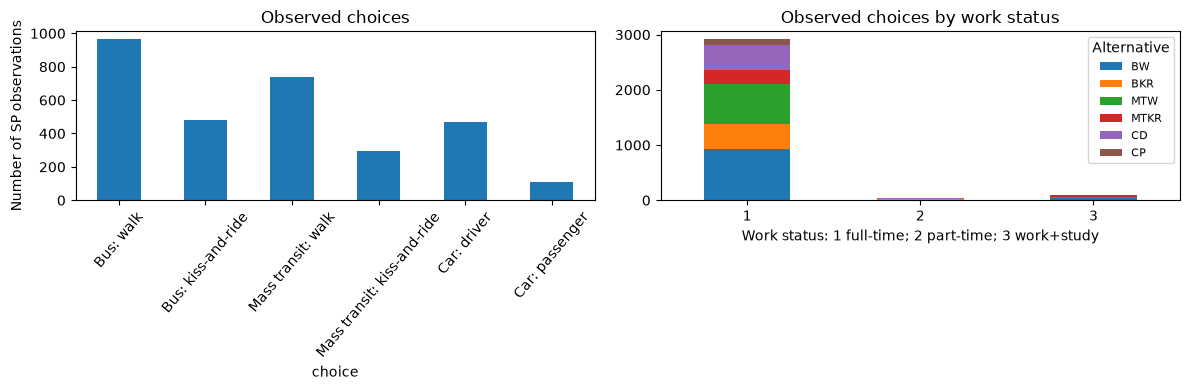

In [5]:
import matplotlib.pyplot as plt  # plotting import (explicit for online Jupyter)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
raw['choice'].map(ALT_LABELS).value_counts().reindex(list(ALT_LABELS.values())).plot(
    kind='bar', ax=axes[0], title='Observed choices')
axes[0].set_ylabel('Number of SP observations')
axes[0].tick_params(axis='x', rotation=50)
work_cross.plot(kind='bar', stacked=True, ax=axes[1], title='Observed choices by work status')
axes[1].set_xlabel('Work status: 1 full-time; 2 part-time; 3 work+study')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Alternative', fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'descriptive_choice_counts.png', dpi=180, bbox_inches='tight')
plt.show()

## 7. Estimate the requested six-alternative MNL

One **generic** travel-time coefficient (`B_TIME`) is shared by every mode. Alternative-specific constants, monetary-cost effects and employment-status effects are estimated wherever the data identify them. The BW constant and employment effects are normalised to zero. No competing models are estimated.

Employment-status interactions with fewer than `MIN_SUBGROUP_CHOICES` chosen records are omitted. The car-passenger cost coefficient is also omitted when its assumed cost is identically zero.


In [6]:
import biogeme
from biogeme.biogeme import BIOGEME
from biogeme.database import Database
from biogeme.expressions import Beta, Variable, PanelLikelihoodTrajectory, log
from biogeme.models import logit
from biogeme.results_processing import get_pandas_estimated_parameters

# Do not estimate employment interactions with no (or too few) chosen records.
eligible_dummy_cells = set()
for dummy_name in ACTIVE_DUMMIES:
    for alt_id, mode in ALT_NAMES.items():
        if alt_id == REFERENCE_ALT:
            continue  # BW is the reference for individual-level characteristics
        n_chosen = int(((data['choice'] == alt_id) & (data[dummy_name] == 1)).sum())
        if n_chosen >= MIN_SUBGROUP_CHOICES:
            eligible_dummy_cells.add((dummy_name, alt_id))
        else:
            print(f'Omitted B_{dummy_name}_{mode}: only {n_chosen} chosen records.')
        if MIN_SUBGROUP_CHOICES <= n_chosen < 10:
            warnings.warn(f'Sparse: {dummy_name} for {mode} has only {n_chosen} chosen records.')

# Repeated SP choices are grouped by respondent.
database = Database('TLV_six_modes', data.copy())
database.panel('rno')

B_TIME = Beta('B_TIME', 0, None, None, 0)  # ONE shared coefficient
utilities = {}
availabilities = {}

for alt_id, mode in ALT_NAMES.items():
    utility = B_TIME * Variable(f'TT_{mode}')

    if alt_id != REFERENCE_ALT:
        utility += Beta(f'ASC_{mode}', 0, None, None, 0)

    cost_column = f'COST_{mode}'
    observed_costs = data.loc[data[f'av{alt_id}'] == 1, cost_column]
    if observed_costs.std() > 1e-12:
        utility += Beta(f'B_COST_{mode}', 0, None, None, 0) * Variable(cost_column)
    elif observed_costs.abs().max() > 1e-12:
        warnings.warn(f'{mode} cost has no variation; a separate cost slope cannot be identified.')

    if alt_id != REFERENCE_ALT:
        for dummy_name in ACTIVE_DUMMIES:
            if (dummy_name, alt_id) in eligible_dummy_cells:
                utility += Beta(f'B_{dummy_name}_{mode}', 0, None, None, 0) * Variable(dummy_name)

    utilities[alt_id] = utility
    availabilities[alt_id] = Variable(f'av{alt_id}')

per_task_probability = logit(utilities, availabilities, Variable('choice'))
log_likelihood = log(PanelLikelihoodTrajectory(per_task_probability))

engine = BIOGEME(database, log_likelihood, generate_html=False, generate_yaml=False)
engine.model_name = MODEL_NAME
print(f'Estimating {MODEL_NAME} ...')
final_result = engine.estimate()
print('Estimation completed. Optimizer converged:', bool(final_result.algorithm_has_converged))

g++ not available, if using conda: `conda install gxx`
c:\Python312\Lib\site-packages\tqdm_joblib\__init__.py:4: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm
C:\Users\bwa125\AppData\Local\Temp\ipykernel_15744\3258359302.py:20: UserWarning: Sparse: WORK2 for BKR has only 7 chosen records.
  warnings.warn(f'Sparse: {dummy_name} for {mode} has only {n_chosen} chosen records.')
C:\Users\bwa125\AppData\Local\Temp\ipykernel_15744\3258359302.py:20: UserWarning: Sparse: WORK2 for MTW has only 7 chosen records.
  warnings.warn(f'Sparse: {dummy_name} for {mode} has only {n_chosen} chosen records.')
C:\Users\bwa125\AppData\Local\Temp\ipykernel_15744\3258359302.py:20: UserWarning: Sparse: WORK3 for CD has only 6 chosen records.
  warnings.warn(f'Sparse: {dummy_name} for {mode} has only {n_chosen} chosen records.')
C:\Users\bwa125\AppData\Local\Temp\ipykernel_15744\32583

Omitted B_WORK2_MTKR: only 0 chosen records.
Omitted B_WORK2_CP: only 0 chosen records.
Estimating Six_Mode_MNL ...
Estimation completed. Optimizer converged: True


## 8. Final calibrated-parameter summary

This final cell reports **only the model estimated above**. It shows model-fit statistics, the complete estimated parameter table with robust inference statistics, and the coefficients arranged by transport alternative. It does **not** rerun estimation.

- Travel time is measured in **10-minute units**, and cost in **NIS**.
- `0 (reference)` denotes a normalised coefficient.
- `—` means a coefficient was not estimated, for example a sparse employment interaction or a car-passenger cost with no observed variation.

In [7]:
# Final summary: uses the results already obtained; no re-estimation.
final_betas = final_result.get_beta_values()
parameter_table = get_pandas_estimated_parameters(estimation_results=final_result)
if isinstance(parameter_table, dict):
    parameter_table = parameter_table.get('Estimated parameters', next(iter(parameter_table.values())))
parameter_table = parameter_table.copy()

ll = float(final_result.raw_estimation_results.final_log_likelihood)
k = len(final_betas)
n_respondents = data['rno'].nunique()
aic = 2 * k - 2 * ll
bic = np.log(n_respondents) * k - 2 * ll

print('=' * 72)
print('FINAL CALIBRATION SUMMARY — SIX-ALTERNATIVE MNL')
print('=' * 72)
print(f'SP observations: {len(data):,} | Respondents: {n_respondents:,}')
print(f'Estimated coefficients: {k} | Converged: {bool(final_result.algorithm_has_converged)}')
print(f'Log-likelihood: {ll:.3f} | AIC: {aic:.3f} | BIC (respondents): {bic:.3f}')

print('\nESTIMATED PARAMETERS (robust standard errors, t-statistics and p-values)')
display(parameter_table.round(5))

# Coefficients in each utility, including fixed/omitted terms for clarity.
row_names = ['ASC', 'Travel time (per 10 min)', 'Cost (per NIS)'] + ACTIVE_DUMMIES
coefficient_matrix = pd.DataFrame('—', index=row_names, columns=list(ALT_NAMES.values()))
for alt_id, mode in ALT_NAMES.items():
    coefficient_matrix.loc['Travel time (per 10 min)', mode] = f"{final_betas['B_TIME']:.5f}"
    coefficient_matrix.loc['ASC', mode] = (
        '0 (reference)' if alt_id == REFERENCE_ALT else f"{final_betas[f'ASC_{mode}']:.5f}"
    )
    cost_key = f'B_COST_{mode}'
    if cost_key in final_betas:
        coefficient_matrix.loc['Cost (per NIS)', mode] = f'{final_betas[cost_key]:.5f}'
    for dummy_name in ACTIVE_DUMMIES:
        key = f'B_{dummy_name}_{mode}'
        if alt_id == REFERENCE_ALT:
            coefficient_matrix.loc[dummy_name, mode] = '0 (reference)'
        elif key in final_betas:
            coefficient_matrix.loc[dummy_name, mode] = f'{final_betas[key]:.5f}'

print('\nUTILITY COEFFICIENTS BY TRANSPORT ALTERNATIVE')
display(coefficient_matrix)

# Simple, portable outputs for the students (both in the same results folder).
parameter_table.to_csv(OUTPUT_DIR / 'calibrated_parameters.csv', index=False)
coefficient_matrix.to_csv(OUTPUT_DIR / 'utility_coefficient_matrix.csv')
print(f'\nCSV tables saved to: {OUTPUT_DIR.resolve()}')

FINAL CALIBRATION SUMMARY — SIX-ALTERNATIVE MNL
SP observations: 3,054 | Respondents: 536
Estimated coefficients: 19 | Converged: True
Log-likelihood: -3906.421 | AIC: 7850.841 | BIC (respondents): 7932.240

ESTIMATED PARAMETERS (robust standard errors, t-statistics and p-values)


,Name,Value,Robust std err.,Robust t-stat.,Robust p-value
0,B_TIME,-0.73631,0.05202,-14.15458,0.00000
1,B_COST_BW,-0.31238,0.04527,-6.90043,0.00000
2,ASC_BKR,-1.43178,0.23646,-6.05507,0.00000
3,B_COST_BKR,-0.20832,0.06946,-2.99901,0.00271
4,B_WORK2_BKR,0.76340,1.18054,0.64665,0.51786
5,B_WORK3_BKR,-0.60840,0.53224,-1.14309,0.25300
6,ASC_MTW,0.63227,0.27697,2.28279,0.02244
7,B_COST_MTW,-0.35883,0.05733,-6.25884,0.00000
8,B_WORK2_MTW,0.89961,0.99172,0.90712,0.36434
9,B_WORK3_MTW,-1.09083,0.54999,-1.98335,0.04733



UTILITY COEFFICIENTS BY TRANSPORT ALTERNATIVE


,BW,BKR,MTW,MTKR,CD,CP
ASC,0 (reference),-1.43178,0.63227,-0.60090,-0.35290,-3.59169
Travel time (per 10 min),-0.73631,-0.73631,-0.73631,-0.73631,-0.73631,-0.73631
Cost (per NIS),-0.31238,-0.20832,-0.35883,-0.36283,-0.02860,—
WORK2,0 (reference),0.76340,0.89961,—,1.51839,—
WORK3,0 (reference),-0.60840,-1.09083,0.92073,-1.69842,-1.14719



CSV tables saved to: C:\Local\Discrete Choice\calibration_results
